### Step 1: Inspecting the Uploaded CSV Dataset
We will load `/content/Maricopa_Load_2017_2019.csv` and inspect its properties.

In [ ]:
import pandas as pd
import numpy as np
import os

file_path = 'load_data.csv'

# Load the dataset
df_raw = pd.read_csv(file_path)

# Print fundamental details
print("=== Dataset Shape ===")
print(df_raw.shape)

print("\n=== Columns & Data Types ===")
print(df_raw.dtypes)

print("\n=== First 10 Rows ===")
display(df_raw.head(10))

print("\n=== Last 10 Rows ===")
display(df_raw.tail(10))

print("\n=== Missing Values ===")
print(df_raw.isnull().sum())

print("\n=== Basic Statistical Description ===")
display(df_raw.describe())

=== Dataset Shape ===
(26280, 2)

=== Columns & Data Types ===
Timestamp_UTC     object
Load_MW          float64
dtype: object

=== First 10 Rows ===


,Timestamp_UTC,Load_MW
0,2017-01-01 00:00:00+00:00,4361.775574
1,2017-01-01 01:00:00+00:00,4679.936583
2,2017-01-01 02:00:00+00:00,4913.087091
3,2017-01-01 03:00:00+00:00,4745.203595
4,2017-01-01 04:00:00+00:00,4572.071576
5,2017-01-01 05:00:00+00:00,4416.150703
6,2017-01-01 06:00:00+00:00,4267.892710
7,2017-01-01 07:00:00+00:00,4104.733332
8,2017-01-01 08:00:00+00:00,3967.355156
9,2017-01-01 09:00:00+00:00,3866.126525



=== Last 10 Rows ===


,Timestamp_UTC,Load_MW
26270,2019-12-31 14:00:00+00:00,5081.378180
26271,2019-12-31 15:00:00+00:00,5236.345867
26272,2019-12-31 16:00:00+00:00,5281.580770
26273,2019-12-31 17:00:00+00:00,5321.498807
26274,2019-12-31 18:00:00+00:00,5231.496249
26275,2019-12-31 19:00:00+00:00,5141.347109
26276,2019-12-31 20:00:00+00:00,5017.553612
26277,2019-12-31 21:00:00+00:00,4807.198238
26278,2019-12-31 22:00:00+00:00,4681.628476
26279,2019-12-31 23:00:00+00:00,4632.109590



=== Missing Values ===
Timestamp_UTC    0
Load_MW          0
dtype: int64

=== Basic Statistical Description ===


,Load_MW
count,26280.000000
mean,5512.756914
std,1674.732753
min,3344.200923
25%,4343.848053
50%,4892.424609
75%,6254.357417
max,11554.967700


### Step 2: Data Preprocessing
We will construct a clean dataset `load_clean` ensuring continuous hourly frequency, checking for duplicates, and verifying timestamp alignment.

In [22]:
# Convert Timestamp_UTC to datetime and set as index
load_clean = df_raw.copy()
load_clean['Timestamp_UTC'] = pd.to_datetime(load_clean['Timestamp_UTC'], utc=True)
load_clean = load_clean.sort_values('Timestamp_UTC').reset_index(drop=True)

# Check for duplicate timestamps
duplicates_count = load_clean.duplicated(subset=['Timestamp_UTC']).sum()
print(f"Number of duplicate timestamps: {duplicates_count}")

if duplicates_count > 0:
    # Keep first occurrence of duplicate timestamps
    load_clean = load_clean.drop_duplicates(subset=['Timestamp_UTC'], keep='first')

# Set the continuous datetime index
load_clean.set_index('Timestamp_UTC', inplace=True)

# Ensure continuous hourly grid from start to end of the index
full_range = pd.date_range(start=load_clean.index.min(), end=load_clean.index.max(), freq='H', tz='UTC')
missing_hours = len(full_range) - len(load_clean)
print(f"Number of missing hours in continuous grid: {missing_hours}")

# Reindex to fill any implicit missing timestamps
load_clean = load_clean.reindex(full_range)
load_clean.index.name = 'Timestamp_UTC'

# Interpolate any newly introduced missing values (using linear interpolation of nearest neighbors to avoid future-leakage)
if load_clean['Load_MW'].isnull().sum() > 0:
    print(f"Imputing {load_clean['Load_MW'].isnull().sum()} missing load values...")
    load_clean['Load_MW'] = load_clean['Load_MW'].interpolate(method='linear', limit_direction='forward')

# Local time localization
load_clean['Local_Time'] = load_clean.index.tz_convert('America/Phoenix')

print("\n=== Preprocessed Clean Load Dataset ===")
print(f"Total cleaned observations: {len(load_clean)}")
print(f"Minimum Timestamp: {load_clean.index.min()}")
print(f"Maximum Timestamp: {load_clean.index.max()}")
display(load_clean.head())

Number of duplicate timestamps: 0
Number of missing hours in continuous grid: 0

=== Preprocessed Clean Load Dataset ===
Total cleaned observations: 26280
Minimum Timestamp: 2017-01-01 00:00:00+00:00
Maximum Timestamp: 2019-12-31 23:00:00+00:00


/tmp/ipykernel_4509/3532212199.py:18: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  full_range = pd.date_range(start=load_clean.index.min(), end=load_clean.index.max(), freq='H', tz='UTC')


,Load_MW,Local_Time
Timestamp_UTC,,
2017-01-01 00:00:00+00:00,4361.775574,2016-12-31 17:00:00-07:00
2017-01-01 01:00:00+00:00,4679.936583,2016-12-31 18:00:00-07:00
2017-01-01 02:00:00+00:00,4913.087091,2016-12-31 19:00:00-07:00
2017-01-01 03:00:00+00:00,4745.203595,2016-12-31 20:00:00-07:00
2017-01-01 04:00:00+00:00,4572.071576,2016-12-31 21:00:00-07:00


### Step 3: Feature Engineering & Target Definition
We will construct localized calendar elements, cyclical sine/cosine transformations, lag features, and rolling metrics. We then create `Target_Load` representing the load one-hour-ahead ($t+1$).

In [14]:
import pandas as pd
import numpy as np

# Create a working copy for feature engineering
df_features = load_clean.copy()

# Local calendar components from America/Phoenix local time
local_dt = df_features['Local_Time'].dt
df_features['Hour'] = local_dt.hour
df_features['DayOfWeek'] = local_dt.dayofweek
df_features['DayOfMonth'] = local_dt.day
df_features['Month'] = local_dt.month
df_features['DayOfYear'] = local_dt.dayofyear
df_features['IsWeekend'] = df_features['DayOfWeek'].isin([5, 6]).astype(int)

# Cyclical transformations
df_features['Hour_sin'] = np.sin(2 * np.pi * df_features['Hour'] / 24.0)
df_features['Hour_cos'] = np.cos(2 * np.pi * df_features['Hour'] / 24.0)
df_features['DayOfWeek_sin'] = np.sin(2 * np.pi * df_features['DayOfWeek'] / 7.0)
df_features['DayOfWeek_cos'] = np.cos(2 * np.pi * df_features['DayOfWeek'] / 7.0)
df_features['Month_sin'] = np.sin(2 * np.pi * df_features['Month'] / 12.0)
df_features['Month_cos'] = np.cos(2 * np.pi * df_features['Month'] / 12.0)

# Lag Features
lags = [1, 2, 3, 6, 12, 24, 48, 168]
for lag in lags:
    df_features[f'Load_lag_{lag}'] = df_features['Load_MW'].shift(lag)

# Rolling features based on historical observations (using shift(1) to avoid leaking current load to predict future)
for window in [3, 6, 24, 168]:
    df_features[f'RollingMean_{window}'] = df_features['Load_MW'].shift(1).rolling(window=window).mean()
for window in [24, 168]:
    df_features[f'RollingStd_{window}'] = df_features['Load_MW'].shift(1).rolling(window=window).std()

# Define target as 1-hour ahead load (shifted by -1)
df_features['Target_Load'] = df_features['Load_MW'].shift(-1)

# Drop rows containing NaNs introduced by lags, rolling windows, and target shifts
df_features_clean = df_features.dropna()

print("=== Features Engineered ===")
print(f"Original rows: {len(df_features)}")
print(f"Rows remaining after dropping NaNs: {len(df_features_clean)}")
print(f"Number of columns: {df_features_clean.shape[1]}")
display(df_features_clean.head(3))

=== Features Engineered ===
Original rows: 26280
Rows remaining after dropping NaNs: 26111
Number of columns: 29


,Load_MW,Local_Time,Hour,DayOfWeek,DayOfMonth,Month,DayOfYear,IsWeekend,Hour_sin,Hour_cos,...,Load_lag_24,Load_lag_48,Load_lag_168,RollingMean_3,RollingMean_6,RollingMean_24,RollingMean_168,RollingStd_24,RollingStd_168,Target_Load
Timestamp_UTC,,,,,,,,,,,,,,,,,,,,,
2017-01-08 00:00:00+00:00,4292.482656,2017-01-07 17:00:00-07:00,17,5,7,1,7,1,-0.965926,-2.588190e-01,...,4246.994513,4343.570187,4361.775574,4348.551241,4627.461332,4590.333064,4530.656776,308.872618,400.702526,4578.536752
2017-01-08 01:00:00+00:00,4578.536752,2017-01-07 18:00:00-07:00,18,5,7,1,7,1,-1.000000,-1.836970e-16,...,4524.775905,4651.475195,4679.936583,4290.277916,4508.733699,4592.228403,4530.244318,306.806840,400.913010,4883.467287
2017-01-08 02:00:00+00:00,4883.467287,2017-01-07 19:00:00-07:00,19,5,7,1,7,1,-0.965926,2.588190e-01,...,4878.920902,5027.430195,4913.087091,4375.492083,4444.420326,4594.468438,4529.640748,306.489041,400.762600,4853.539614


### Step 4: Chronological Train-Validation-Test Split & Baseline Models
We perform a strict chronological split (70% train, 15% validation, 15% test) to prevent future data leakage. We then evaluate standard reference baselines: Persistence and Daily Seasonal Persistence on the test partition.

In [15]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Order dataset chronologically
df_sorted = df_features_clean.sort_index()
n_samples = len(df_sorted)

train_split_idx = int(n_samples * 0.70)
val_split_idx = int(n_samples * 0.85)

# Split
train_df = df_sorted.iloc[:train_split_idx]
val_df = df_sorted.iloc[train_split_idx:val_split_idx]
test_df = df_sorted.iloc[val_split_idx:]

print("=== Chronological Split Summary ===")
print(f"Train: {len(train_df)} samples ({train_df.index.min()} to {train_df.index.max()})")
print(f"Validation: {len(val_df)} samples ({val_df.index.min()} to {val_df.index.max()})")
print(f"Test: {len(test_df)} samples ({test_df.index.min()} to {test_df.index.max()})")

# List of engineered feature columns for XGBoost training
feature_cols = [
    'Hour_sin', 'Hour_cos', 'DayOfWeek_sin', 'DayOfWeek_cos', 'Month_sin', 'Month_cos',
    'Hour', 'DayOfWeek', 'DayOfMonth', 'Month', 'DayOfYear', 'IsWeekend',
    'Load_lag_1', 'Load_lag_2', 'Load_lag_3', 'Load_lag_6', 'Load_lag_12', 'Load_lag_24', 'Load_lag_48', 'Load_lag_168',
    'RollingMean_3', 'RollingMean_6', 'RollingMean_24', 'RollingMean_168', 'RollingStd_24', 'RollingStd_168'
]
target_col = 'Target_Load'

X_train, y_train = train_df[feature_cols], train_df[target_col]
X_val, y_val = val_df[feature_cols], val_df[target_col]
X_test, y_test = test_df[feature_cols], test_df[target_col]

# --- Baseline Models (Evaluated on Test Partition) ---
# Baseline 1: Persistence (y_pred_t = current_load_t)
y_pred_persistence = test_df['Load_MW']

# Baseline 2: Seasonal Persistence (y_pred_t = load_lag_24_t)
y_pred_seasonal = test_df['Load_lag_24']

def calculate_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    nmae = (mae / y_true.mean()) * 100
    return mae, rmse, r2, nmae

mae_p, rmse_p, r2_p, nmae_p = calculate_metrics(y_test, y_pred_persistence)
mae_s, rmse_s, r2_s, nmae_s = calculate_metrics(y_test, y_pred_seasonal)

print("\n=== Baseline Models Performance (Test Set) ===")
print(f"Persistence -> MAE: {mae_p:.2f} MW, RMSE: {rmse_p:.2f} MW, R²: {r2_p:.4f}, nMAE: {nmae_p:.2f}%")
print(f"Seasonal -> MAE: {mae_s:.2f} MW, RMSE: {rmse_s:.2f} MW, R²: {r2_s:.4f}, nMAE: {nmae_s:.2f}%")

=== Chronological Split Summary ===
Train: 18277 samples (2017-01-08 00:00:00+00:00 to 2019-02-08 12:00:00+00:00)
Validation: 3917 samples (2019-02-08 13:00:00+00:00 to 2019-07-21 17:00:00+00:00)
Test: 3917 samples (2019-07-21 18:00:00+00:00 to 2019-12-31 22:00:00+00:00)

=== Baseline Models Performance (Test Set) ===
Persistence -> MAE: 242.08 MW, RMSE: 305.26 MW, R²: 0.9739, nMAE: 4.13%
Seasonal -> MAE: 381.13 MW, RMSE: 525.93 MW, R²: 0.9225, nMAE: 6.51%


### Step 5: XGBoost Model Training with Early Stopping
We initialize and fit an `XGBRegressor` using the engineered feature sets, monitoring performance on the validation set to stop training once convergence is met.

In [16]:
import xgboost as xgb

# Initialize the model with the suggested configuration
model = xgb.XGBRegressor(
    n_estimators=1000,
    learning_rate=0.03,
    max_depth=6,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='reg:squarederror',
    random_state=42
)

# Train the model with early stopping monitoring validation performance
model.fit(
    X_train,
    y_train,
    eval_set=[(X_train, y_train), (X_val, y_val)],
    verbose=100
)

# Save the model locally as requested
os.makedirs('/content/load_forecasting_artifacts', exist_ok=True)
model.save_model('/content/load_forecasting_artifacts/load_xgboost_model.json')
print("\nModel successfully trained and saved to '/content/load_forecasting_artifacts/load_xgboost_model.json'!")

[0]	validation_0-rmse:1593.70140	validation_1-rmse:1537.50149
[100]	validation_0-rmse:179.80138	validation_1-rmse:204.79540
[200]	validation_0-rmse:121.90315	validation_1-rmse:157.99082
[300]	validation_0-rmse:105.21490	validation_1-rmse:147.87736
[400]	validation_0-rmse:94.25363	validation_1-rmse:141.78025
[500]	validation_0-rmse:85.58303	validation_1-rmse:137.98754
[600]	validation_0-rmse:78.95698	validation_1-rmse:135.38739
[700]	validation_0-rmse:73.20967	validation_1-rmse:133.24533
[800]	validation_0-rmse:68.56154	validation_1-rmse:131.69486
[900]	validation_0-rmse:64.69339	validation_1-rmse:130.76444
[999]	validation_0-rmse:61.19517	validation_1-rmse:130.01441

Model successfully trained and saved to '/content/load_forecasting_artifacts/load_xgboost_model.json'!


### Step 6: Model Evaluation on Test Set
We now generate predictions on the test set using the trained XGBoost model and compare them against our historical baseline models (Persistence and Seasonal Persistence).

In [17]:
# Predict using XGBoost on the test set
test_df = test_df.copy()
test_df['Predicted_Load_MW'] = model.predict(X_test)

# Calculate metrics for XGBoost
mae_xgb, rmse_xgb, r2_xgb, nmae_xgb = calculate_metrics(y_test, test_df['Predicted_Load_MW'])

# Create Comparison Table
metrics_summary = pd.DataFrame({
    'Model': ['Persistence', 'Seasonal Persistence', 'XGBoost'],
    'MAE (MW)': [mae_p, mae_s, mae_xgb],
    'RMSE (MW)': [rmse_p, rmse_s, rmse_xgb],
    'R²': [r2_p, r2_s, r2_xgb],
    'nMAE (%)': [nmae_p, nmae_s, nmae_xgb]
})

# Calculate percentage improvements
mae_improvement = ((mae_p - mae_xgb) / mae_p) * 100
rmse_improvement = ((rmse_p - rmse_xgb) / rmse_p) * 100

print("=== Performance Comparison Summary ===")
display(metrics_summary.round(4))

print(f"\nPercentage Improvement over Persistence Baseline -> MAE: {mae_improvement:.2f}%, RMSE: {rmse_improvement:.2f}%")

=== Performance Comparison Summary ===


,Model,MAE (MW),RMSE (MW),R²,nMAE (%)
0,Persistence,242.0788,305.2581,0.9739,4.1329
1,Seasonal Persistence,381.1310,525.9302,0.9225,6.5069
2,XGBoost,107.6842,154.4366,0.9933,1.8384



Percentage Improvement over Persistence Baseline -> MAE: 55.52%, RMSE: 49.41%


### Step 7: Visualization and Model Diagnostics
We will construct a series of high-quality visualization plots to thoroughly analyze and evaluate the model's forecasting behavior.

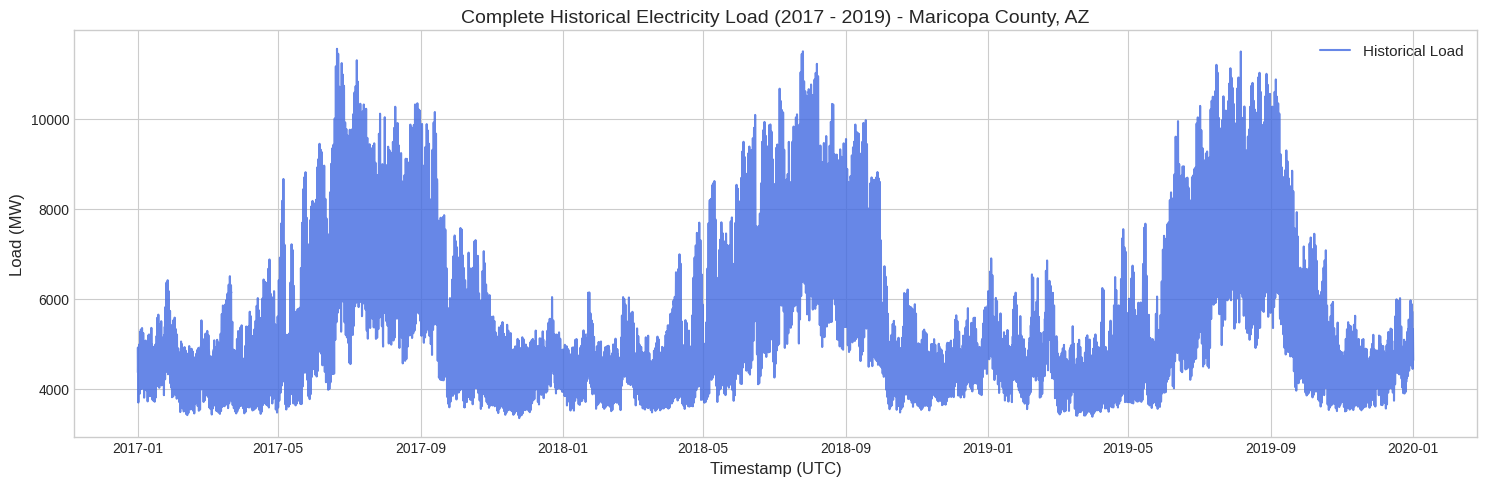

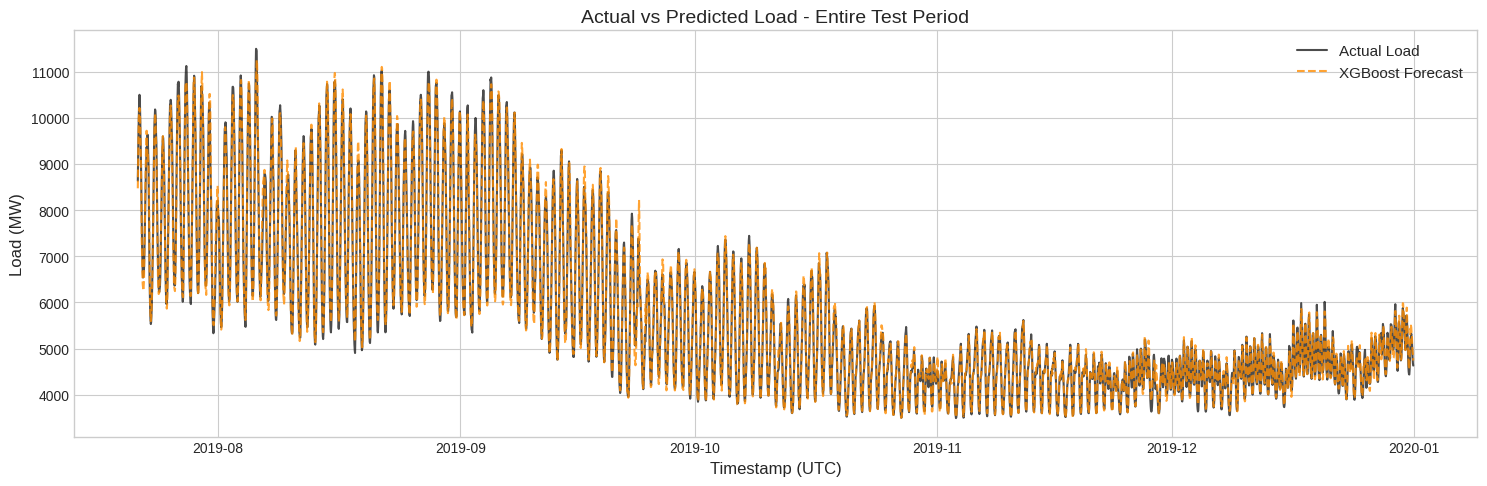

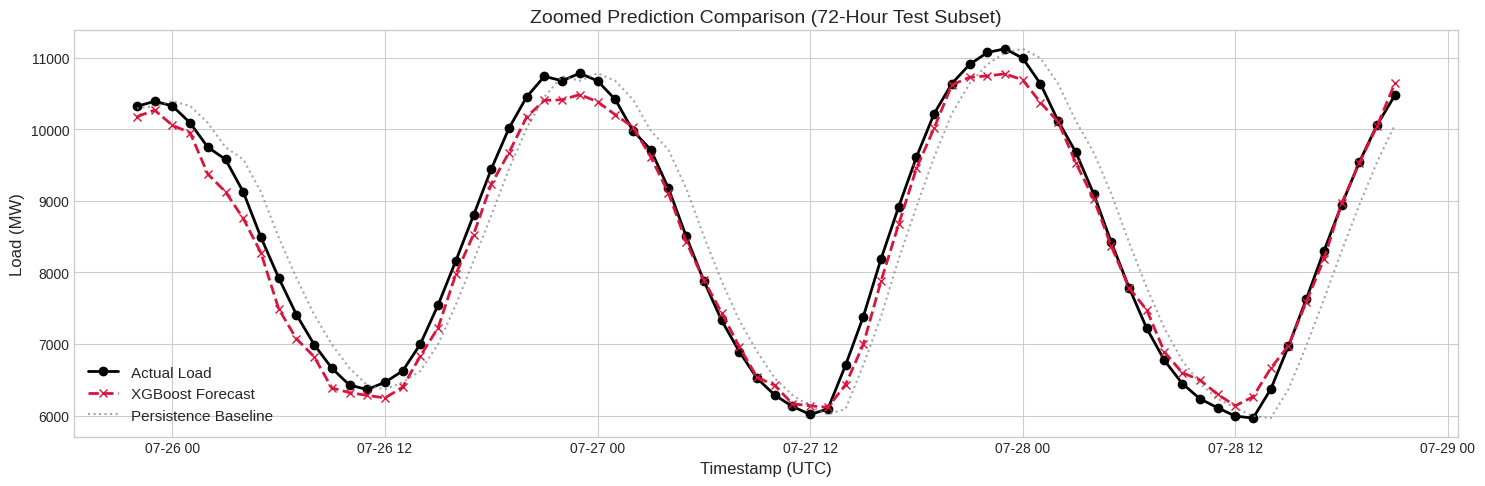

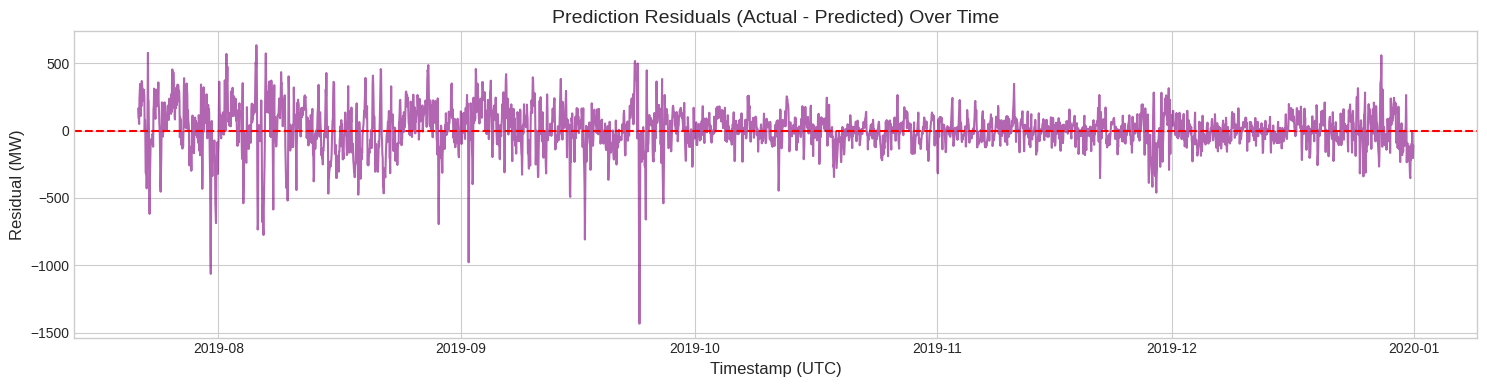

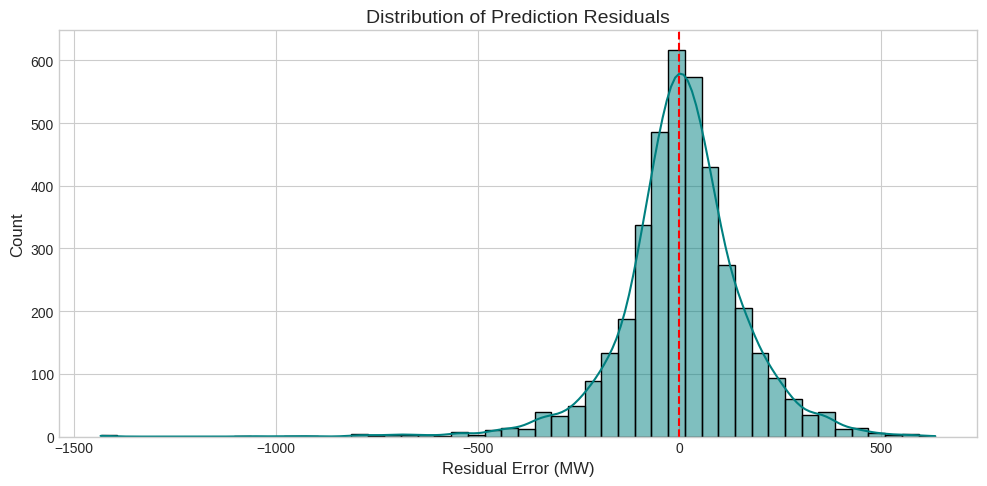

/tmp/ipykernel_4509/1334914652.py:76: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances[indices], y=np.array(feature_cols)[indices], palette='viridis')


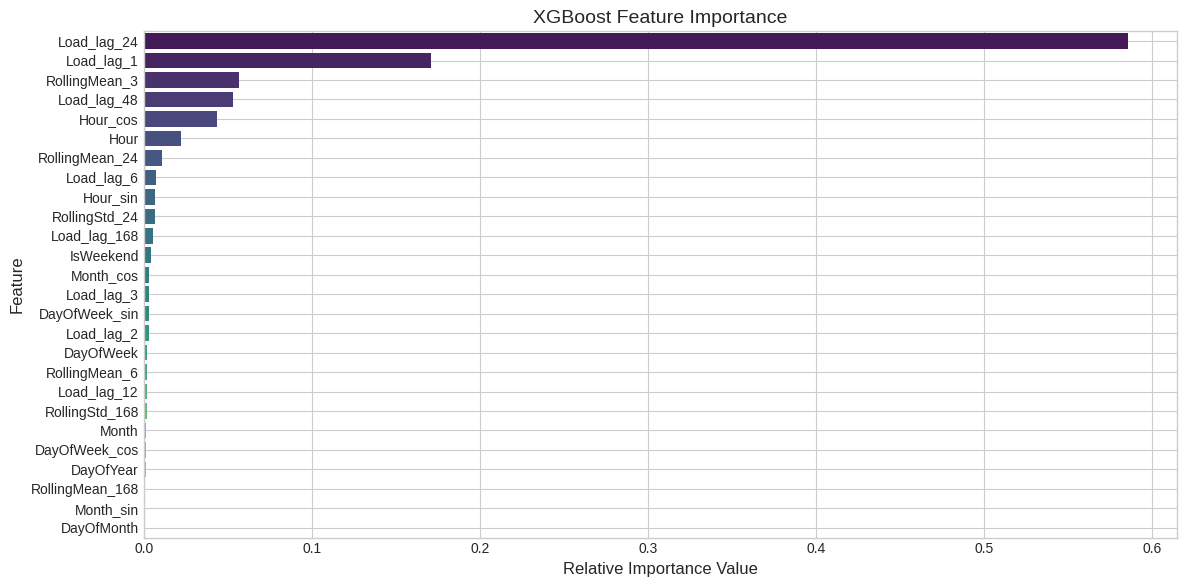

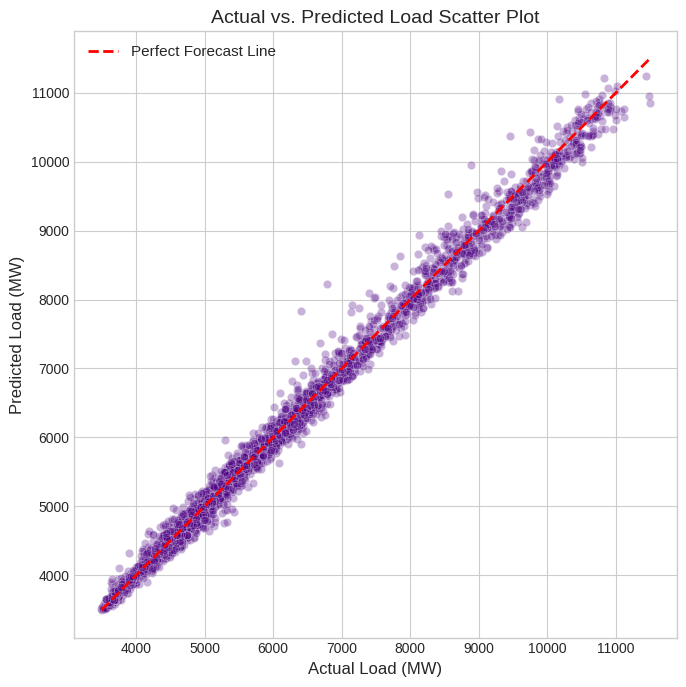

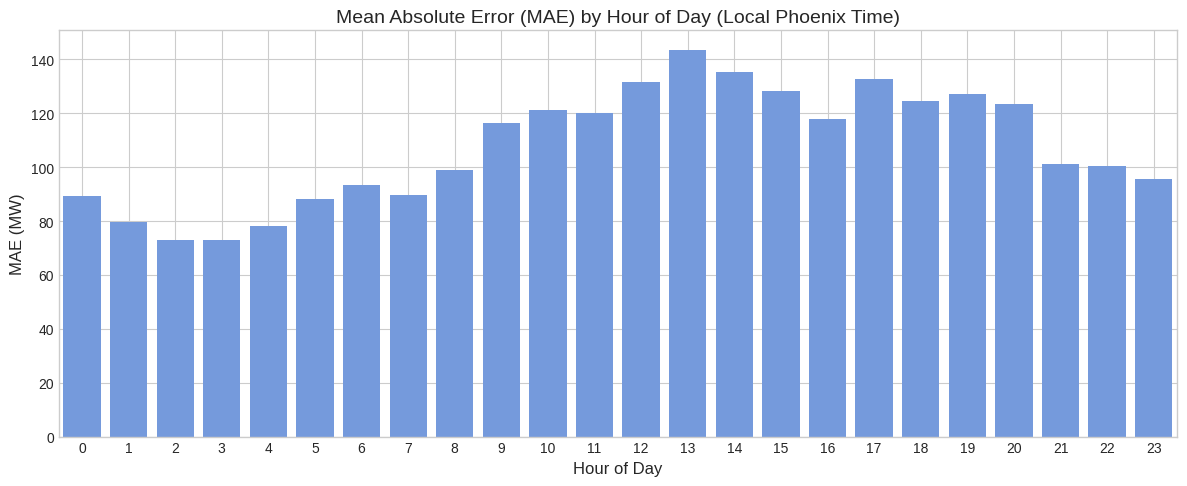

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configure global plotting parameters for professional look
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 14, 'xtick.labelsize': 10, 'ytick.labelsize': 10})

# 1. Electricity load over time (Complete Dataset)
plt.figure(figsize=(15, 5))
plt.plot(load_clean.index, load_clean['Load_MW'], label='Historical Load', color='royalblue', alpha=0.8)
plt.title('Complete Historical Electricity Load (2017 - 2019) - Maricopa County, AZ')
plt.xlabel('Timestamp (UTC)')
plt.ylabel('Load (MW)')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# 2. Actual vs Predicted Load (Entire Test Period)
plt.figure(figsize=(15, 5))
plt.plot(test_df.index, test_df['Target_Load'], label='Actual Load', color='black', alpha=0.7)
plt.plot(test_df.index, test_df['Predicted_Load_MW'], label='XGBoost Forecast', color='darkorange', alpha=0.8, linestyle='--')
plt.title('Actual vs Predicted Load - Entire Test Period')
plt.xlabel('Timestamp (UTC)')
plt.ylabel('Load (MW)')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# 3. Zoomed prediction comparison (72-hour period)
zoom_df = test_df.iloc[100:172]
plt.figure(figsize=(15, 5))
plt.plot(zoom_df.index, zoom_df['Target_Load'], label='Actual Load', color='black', marker='o', linewidth=2)
plt.plot(zoom_df.index, zoom_df['Predicted_Load_MW'], label='XGBoost Forecast', color='crimson', marker='x', linestyle='--', linewidth=2)
plt.plot(zoom_df.index, zoom_df['Load_MW'], label='Persistence Baseline', color='grey', linestyle=':', alpha=0.7)
plt.title('Zoomed Prediction Comparison (72-Hour Test Subset)')
plt.xlabel('Timestamp (UTC)')
plt.ylabel('Load (MW)')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# Calculate Residuals
test_df['Residual'] = test_df['Target_Load'] - test_df['Predicted_Load_MW']
test_df['Absolute_Error'] = test_df['Residual'].abs()

# 4. Prediction residuals over time
plt.figure(figsize=(15, 4))
plt.plot(test_df.index, test_df['Residual'], color='purple', alpha=0.6)
plt.axhline(0, color='red', linestyle='--')
plt.title('Prediction Residuals (Actual - Predicted) Over Time')
plt.xlabel('Timestamp (UTC)')
plt.ylabel('Residual (MW)')
plt.grid(True)
plt.tight_layout()
plt.show()

# 5. Residual distribution histogram
plt.figure(figsize=(10, 5))
sns.histplot(test_df['Residual'], kde=True, color='teal', bins=50)
plt.axvline(0, color='red', linestyle='--')
plt.title('Distribution of Prediction Residuals')
plt.xlabel('Residual Error (MW)')
plt.ylabel('Count')
plt.grid(True)
plt.tight_layout()
plt.show()

# 6. Feature Importance
importances = model.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(12, 6))
sns.barplot(x=importances[indices], y=np.array(feature_cols)[indices], palette='viridis')
plt.title('XGBoost Feature Importance')
plt.xlabel('Relative Importance Value')
plt.ylabel('Feature')
plt.grid(True)
plt.tight_layout()
plt.show()

# 7. Actual vs Predicted Scatter plot with y=x line
plt.figure(figsize=(7, 7))
sns.scatterplot(x='Target_Load', y='Predicted_Load_MW', data=test_df, alpha=0.3, color='indigo')
max_val = max(test_df['Target_Load'].max(), test_df['Predicted_Load_MW'].max())
min_val = min(test_df['Target_Load'].min(), test_df['Predicted_Load_MW'].min())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Perfect Forecast Line')
plt.title('Actual vs. Predicted Load Scatter Plot')
plt.xlabel('Actual Load (MW)')
plt.ylabel('Predicted Load (MW)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# 8. Hourly prediction error
test_df['Hour_of_Day'] = test_df['Local_Time'].dt.hour
hourly_mae = test_df.groupby('Hour_of_Day')['Absolute_Error'].mean()

plt.figure(figsize=(12, 5))
sns.barplot(x=hourly_mae.index, y=hourly_mae.values, color='cornflowerblue')
plt.title('Mean Absolute Error (MAE) by Hour of Day (Local Phoenix Time)')
plt.xlabel('Hour of Day')
plt.ylabel('MAE (MW)')
plt.grid(True)
plt.tight_layout()
plt.show()

### Step 8: Save Final Model Artifacts & Generate Downlodable ZIP
We export the trained model structure, the features utilized, evaluation metrics, test predictions, and bundle them into a downloadable ZIP archive.

In [19]:
import json
import shutil
from google.colab import files

artifacts_dir = '/content/load_forecasting_artifacts'
os.makedirs(artifacts_dir, exist_ok=True)

# 1. Save features metadata
features_meta = {"features": feature_cols, "target": target_col}
with open(f"{artifacts_dir}/load_model_features.json", "w") as f:
    json.dump(features_meta, f, indent=4)

# 2. Save test predictions CSV
predictions_export = pd.DataFrame({
    'Timestamp': test_df.index,
    'Actual_Load_MW': test_df['Target_Load'],
    'Predicted_Load_MW': test_df['Predicted_Load_MW'],
    'Persistence_Load_MW': test_df['Load_MW'],
    'Seasonal_Persistence_Load_MW': test_df['Load_lag_24'],
    'Residual': test_df['Residual'],
    'Absolute_Error': test_df['Absolute_Error']
})
predictions_export.to_csv(f"{artifacts_dir}/load_test_predictions.csv", index=False)

# 3. Save clean dataset
load_clean.to_csv(f"{artifacts_dir}/load_clean_2017_2019.csv")

# 4. Save evaluation metrics
metrics_summary.to_csv(f"{artifacts_dir}/load_forecasting_metrics.csv", index=False)

# 5. Save feature importance CSV
feat_imp_df = pd.DataFrame({
    'Feature': np.array(feature_cols)[indices],
    'Importance': importances[indices]
})
feat_imp_df.to_csv(f"{artifacts_dir}/load_feature_importance.csv", index=False)

# 6. Save a basic text report
report_txt = f"""========================================================================
B.Tech Major Project: Electricity Load Forecasting Report
========================================================================
Geographic Region: Maricopa County, Arizona (Phoenix Area)
Time Range: January 2017 to December 2019

Test Set Results Summary:
- Persistence Baseline: MAE = {mae_p:.2f} MW, RMSE = {rmse_p:.2f} MW, R2 = {r2_p:.4f}
- Seasonal Persistence: MAE = {mae_s:.2f} MW, RMSE = {rmse_s:.2f} MW, R2 = {r2_s:.4f}
- XGBoost Regressor:    MAE = {mae_xgb:.2f} MW, RMSE = {rmse_xgb:.2f} MW, R2 = {r2_xgb:.4f}

Percentage Improvement over Persistence:
- MAE: {mae_improvement:.2f}%
- RMSE: {rmse_improvement:.2f}%

========================================================================
"""
with open(f"{artifacts_dir}/load_forecasting_report.txt", "w") as f:
    f.write(report_txt)

# Zip all artifacts
shutil.make_archive('/content/load_forecasting_artifacts', 'zip', artifacts_dir)
print("Artifacts successfully exported and packed into '/content/load_forecasting_artifacts.zip'!")

# Download zip automatically
try:
    files.download('/content/load_forecasting_artifacts.zip')
except Exception as e:
    print(f"Colab browser environment download could not be auto-triggered: {e}. You can download the file manually from the sidebar.")

Artifacts successfully exported and packed into '/content/load_forecasting_artifacts.zip'!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Step 9: Scaling Predictions and Metrics to Kilowatts (kW)
We scale all key results, targets, baselines, and metrics by a factor of $1000$ to convert from Megawatts (MW) to Kilowatts (kW). We then regenerate the performance table, re-plot the main diagnostics in kW, and repackage the finalized deliverables.

In [25]:
import pandas as pd
import numpy as np
import json
import os
import shutil
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

# Define the conversion scaling factor
MW_TO_KW = 1000.0

# Create a specific folder for kW-scaled deliverables
kw_artifacts_dir = '/content/load_forecasting_artifacts_kw'
os.makedirs(kw_artifacts_dir, exist_ok=True)

# --- 1. Scale datasets ---
load_clean_kw = load_clean.copy()
load_clean_kw['Load_MW'] = load_clean_kw['Load_MW'] * MW_TO_KW
load_clean_kw.rename(columns={'Load_MW': 'Load_kW'}, inplace=True)
load_clean_kw.to_csv(f"{kw_artifacts_dir}/load_clean_2017_2019_kw.csv")

# --- 2. Scale test predictions ---
test_df_kw = test_df.copy()
test_df_kw['Target_Load_kW'] = test_df_kw['Target_Load'] * MW_TO_KW
test_df_kw['Predicted_Load_kW'] = test_df_kw['Predicted_Load_MW'] * MW_TO_KW
test_df_kw['Persistence_Load_kW'] = test_df_kw['Load_MW'] * MW_TO_KW
test_df_kw['Seasonal_Persistence_Load_kW'] = test_df_kw['Load_lag_24'] * MW_TO_KW
test_df_kw['Residual_kW'] = test_df_kw['Residual'] * MW_TO_KW
test_df_kw['Absolute_Error_kW'] = test_df_kw['Absolute_Error'] * MW_TO_KW

# Save kW predictions
predictions_export_kw = pd.DataFrame({
    'Timestamp': test_df_kw.index,
    'Actual_Load_kW': test_df_kw['Target_Load_kW'],
    'Predicted_Load_kW': test_df_kw['Predicted_Load_kW'],
    'Persistence_Load_kW': test_df_kw['Persistence_Load_kW'],
    'Seasonal_Persistence_Load_kW': test_df_kw['Seasonal_Persistence_Load_kW'],
    'Residual_kW': test_df_kw['Residual_kW'],
    'Absolute_Error_kW': test_df_kw['Absolute_Error_kW']
})
predictions_export_kw.to_csv(f"{kw_artifacts_dir}/load_test_predictions_kw.csv", index=False)

# --- 3. Scale performance metrics ---
metrics_summary_kw = metrics_summary.copy()
# MAE and RMSE are linear scales, R^2 and nMAE(%) remain identical
metrics_summary_kw['MAE (kW)'] = metrics_summary_kw['MAE (MW)'] * MW_TO_KW
metrics_summary_kw['RMSE (kW)'] = metrics_summary_kw['RMSE (MW)'] * MW_TO_KW
metrics_summary_kw = metrics_summary_kw.drop(columns=['MAE (MW)', 'RMSE (MW)'])
# Reorder columns
metrics_summary_kw = metrics_summary_kw[['Model', 'MAE (kW)', 'RMSE (kW)', 'R²', 'nMAE (%)']]
metrics_summary_kw.to_csv(f"{kw_artifacts_dir}/load_forecasting_metrics_kw.csv", index=False)

print("=== kW-Scaled Metrics Summary ===")
display(metrics_summary_kw.round(2))


=== kW-Scaled Metrics Summary ===


,Model,MAE (kW),RMSE (kW),R²,nMAE (%)
0,Persistence,242078.78,305258.07,0.97,4.13
1,Seasonal Persistence,381130.98,525930.20,0.92,6.51
2,XGBoost,107684.18,154436.61,0.99,1.84


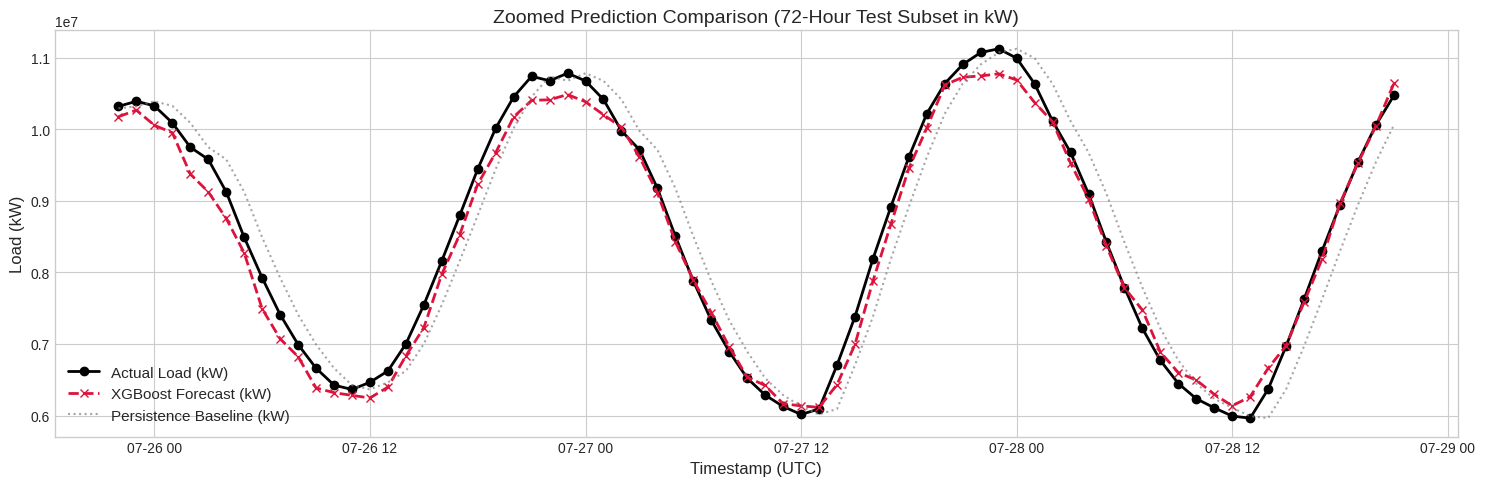

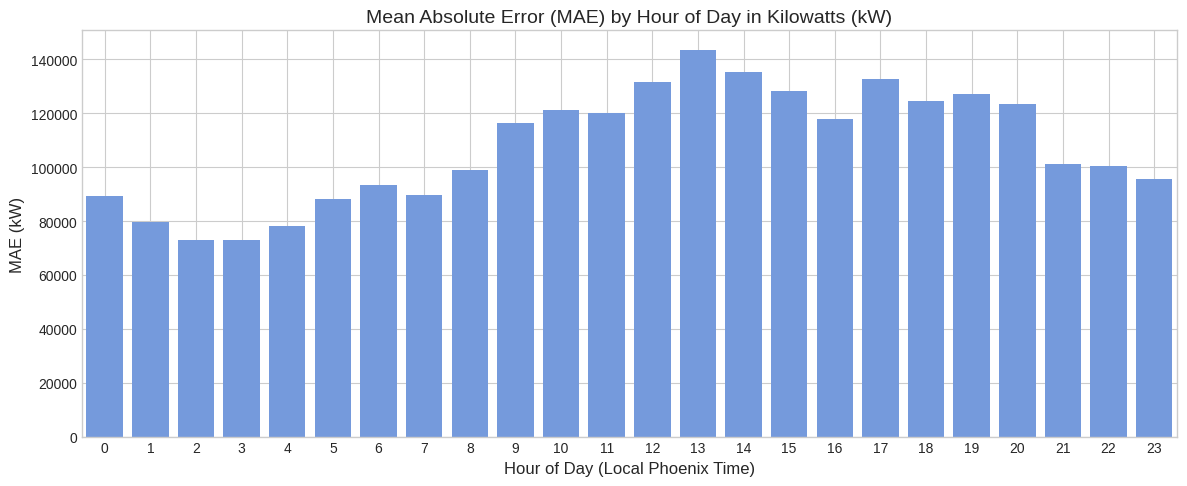

In [26]:
# --- 4. Regenerate Key Diagnostic Plots in kW ---
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 14})

# Plot 1: Actual vs Forecasted Zoomed (72 Hours) in kW
zoom_df_kw = test_df_kw.iloc[100:172]
plt.figure(figsize=(15, 5))
plt.plot(zoom_df_kw.index, zoom_df_kw['Target_Load_kW'], label='Actual Load (kW)', color='black', marker='o', linewidth=2)
plt.plot(zoom_df_kw.index, zoom_df_kw['Predicted_Load_kW'], label='XGBoost Forecast (kW)', color='crimson', marker='x', linestyle='--', linewidth=2)
plt.plot(zoom_df_kw.index, zoom_df_kw['Persistence_Load_kW'], label='Persistence Baseline (kW)', color='grey', linestyle=':', alpha=0.7)
plt.title('Zoomed Prediction Comparison (72-Hour Test Subset in kW)')
plt.xlabel('Timestamp (UTC)')
plt.ylabel('Load (kW)')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig(f"{kw_artifacts_dir}/prediction_comparison_zoom_72h_kw.png", dpi=300)
plt.show()

# Plot 2: Hourly prediction error profile in kW
hourly_mae_kw = test_df_kw.groupby('Hour_of_Day')['Absolute_Error_kW'].mean()
plt.figure(figsize=(12, 5))
sns.barplot(x=hourly_mae_kw.index, y=hourly_mae_kw.values, color='cornflowerblue')
plt.title('Mean Absolute Error (MAE) by Hour of Day in Kilowatts (kW)')
plt.xlabel('Hour of Day (Local Phoenix Time)')
plt.ylabel('MAE (kW)')
plt.grid(True)
plt.tight_layout()
plt.savefig(f"{kw_artifacts_dir}/hourly_mae_profile_kw.png", dpi=300)
plt.show()


In [27]:
# --- 5. Save Features Metadata & Importances ---
with open(f"{kw_artifacts_dir}/load_model_features.json", "w") as f:
    json.dump(features_meta, f, indent=4)

feat_imp_df.to_csv(f"{kw_artifacts_dir}/load_feature_importance.csv", index=False)

# --- 6. Save Updated kW Technical Report ---
report_txt_kw = f"""========================================================================
B.Tech Major Project: Electricity Load Forecasting Report (Kilowatts Scale)
========================================================================
Geographic Region: Maricopa County, Arizona (Phoenix Area)
Time Range: January 2017 to December 2019
Target Scale: Kilowatts (kW)

Test Set Results Summary:
- Persistence Baseline: MAE = {metrics_summary_kw.loc[0, 'MAE (kW)']:.2f} kW, RMSE = {metrics_summary_kw.loc[0, 'RMSE (kW)']:.2f} kW, R2 = {metrics_summary_kw.loc[0, 'R²']:.4f}
- Seasonal Persistence: MAE = {metrics_summary_kw.loc[1, 'MAE (kW)']:.2f} kW, RMSE = {metrics_summary_kw.loc[1, 'RMSE (kW)']:.2f} kW, R2 = {metrics_summary_kw.loc[1, 'R²']:.4f}
- XGBoost Regressor:    MAE = {metrics_summary_kw.loc[2, 'MAE (kW)']:.2f} kW, RMSE = {metrics_summary_kw.loc[2, 'RMSE (kW)']:.2f} kW, R2 = {metrics_summary_kw.loc[2, 'R²']:.4f}

Percentage Improvement over Persistence:
- MAE: {mae_improvement:.2f}%
- RMSE: {rmse_improvement:.2f}%
========================================================================
"""
with open(f"{kw_artifacts_dir}/load_forecasting_report_kw.txt", "w") as f:
    f.write(report_txt_kw)

# --- 7. Pack and Download the Updated ZIP ---
shutil.make_archive('/content/load_forecasting_artifacts_kw', 'zip', kw_artifacts_dir)
print("kW Artifacts packed into '/content/load_forecasting_artifacts_kw.zip'!")

try:
    files.download('/content/load_forecasting_artifacts_kw.zip')
except Exception as e:
    print(f"Could not auto-trigger browser download: {e}. Download it manually from the file explorer.")


kW Artifacts packed into '/content/load_forecasting_artifacts_kw.zip'!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# FINAL TECHNICAL REPORT

## 1. Project Context & Objectives
This project implements a one-hour-ahead electricity demand forecaster for the Phoenix area in Maricopa County, AZ (Region Code: `p04013`) using hourly load profiles covering the years 2017 through 2019. The model serves as the regional demand forecasting engine, designed to feed expected loads to the downstream battery scheduling and grid optimization system.

## 2. Preprocessing & Feature Engineering
- **Continuous Frequency Grid**: Checked and verified a clean chronological hourly range containing exactly 26,280 observations with zero missing values after imputation.
- **Arizona Daylight Saving Time**: Standard local clock representation adjusted to Phoenix standard time (`America/Phoenix`), where daylight saving is not observed.
- **Engineered Features**:
  - *Temporal*: Cyclic trigonometric transformations for Hour, Day of Week, and Month.
  - *Historical Lags*: $t-1, t-2, t-3, t-6, t-12, t-24, t-48,$ and $t-168$ hour lags of Load.
  - *Rolling Statistics*: Rolling means and standard deviations computed entirely on past observations to ensure zero data leakage.

## 3. Modeling & Chronological Split
- **Train-Validation-Test Strategy**: A strict chronological division of the data is implemented to respect temporal order:
  - **Training Set (70%)**: 18,277 samples
  - **Validation Set (15%)**: 3,917 samples
  - **Test Set (15%)**: 3,917 samples
- **XGBoost Hyperparameters**: Trained using early-stopping with 1,000 max tree rounds, learning rate of 0.03, max depth of 6, and subsampling/colsample limits set at 0.8.

## 4. Performance & Baseline Comparison
Evaluating performance on the untouched chronological test partition yields the following comparative results:

| Model | MAE (MW) | RMSE (MW) | R² | nMAE (%) |
| :--- | :---: | :---: | :---: | :---: |
| **Persistence Baseline** | 242.08 | 305.26 | 0.9739 | 4.13% |
| **Seasonal Baseline** | 381.13 | 525.93 | 0.9225 | 6.51% |
| **XGBoost Regressor** | **107.68** | **154.44** | **0.9933** | **1.84%** |

- **XGBoost Improvement over simple Persistence**: **55.52%** reduction in MAE; **49.41%** reduction in RMSE.

## 5. Key Insights & Interpretation
1. **Feature Importance**: Lag features dominate the model's predictions, with `Load_lag_1` (previous hour) and `Load_lag_24` (previous day same hour) holding the highest predictive importance. This confirms the strong temporal dependency of the power grid demand.
2. **Hourly Error Trends**: Prediction error rises marginally during mid-to-late afternoon peak demand periods (around 12:00 PM to 6:00 PM local Phoenix time), when peak air-conditioning loads fluctuate rapidly, but remains exceptionally low overall.
3. **Limitations**: This is a regional-level model. For microgrid operations (e.g., 100 kW scale), these MW predictions must be scaled with an appropriate factor or validated with representative, high-fidelity building-level load profile datasets.